In [1]:
using QuantumCollocation
using NamedTrajectories
using TrajectoryIndexingUtils

using CairoMakie
using DelimitedFiles
using Distributions
using LinearAlgebra
using SparseArrays
pathof(QuantumCollocation)

"/home/andy/Documents/Research/JuliaPackages/StealthPICO/src/QuantumCollocation.jl"

In [2]:
# Operators 
const n_levels = 2
const a⁺ = create(n_levels)
const a⁻ = annihilate(n_levels)

const H_ops = Dict(
        "X" => a⁻ + a⁺,
        "Y" => -im * (a⁻ - a⁺),
        "Z" => I - 2 * a⁺ * a⁻,
)

# Time
const T = 54
const Δt = 2/9

# Basic gates
const I_gate = Matrix{ComplexF64}(I, 2, 2)
const X_gate = GATES[:X]
const SX_gate = sqrt(GATES[:X])

2×2 Matrix{ComplexF64}:
 0.5+0.5im  0.5-0.5im
 0.5-0.5im  0.5+0.5im

In [8]:
case = "5qubits"
if case == "4qubits"
    neighbors = [join([(i == j || i == mod(j, 4) + 1) ? "Z" : "I" for i in 1:4]) for j in 1:4]
    dephasing = [join([(i == j) ? "Z" : "I" for i in 1:4]) for j in 1:4]
    crosstalk_labels = vcat(neighbors, dephasing)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:4]) for j in 1:4]

    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate])
    a_guess = (π/2/T/Δt) * ones((length(H_controls), T))

elseif case == "6qubits"
    neighbors = [join([(i == j || i == mod(j, 6) + 1) ? "Z" : "I" for i in 1:6]) for j in 1:6]
    diagonals = [join([(i == j || i == mod(j, 6) + 3) ? "Z" : "I" for i in 1:6]) for j in 1:3]
    # Dephasing unnecessary because of identity
    # dephasing = [join([(i == j) ? "Z" : "I" for i in 1:6]) for j in 1:6]
    crosstalk_labels = vcat(neighbors, diagonals)
    H_crosstalk = sum(kron_from_dict(n, H_ops) for n in crosstalk_labels)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:6]) for j in 1:6]
    
    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate, I_gate, I_gate])
    a_guess = (π/2/T/Δt) * ones((length(H_controls), T))

elseif case == "5qubits"
    # don't loop back around
    neighbors = [join([(i == j || i == mod(j, 5) + 1) ? "Z" : "I" for i in 1:5]) for j in 1:4]
    diagonals = [join([(i == j || i == mod(j, 5) + 3) ? "Z" : "I" for i in 1:5]) for j in 1:2]
    # technically only need odds (evens play next to shaped identity)
    dephasing = [join([(i == j) ? "Z" : "I" for i in 1:5]) for j in [1,3,5]]
    crosstalk_labels = vcat(neighbors, diagonals, dephasing)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:5]) for j in 1:5]

    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate, I_gate])

    # a_guess = stack(
    #     [(π + π/2)/T/Δt * ones(T),
    #     π/2/T/Δt * ones(T),
    #     (π + π/4)/T/Δt * ones(T),
    #     π/4/T/Δt * ones(T),
    #     π/T/Δt * ones(T)],
    #     dims=1
    # )

    a_guess = π/4/T/Δt * ones(length(H_controls), T)
end;

In [10]:
H_controls = [kron_from_dict(n, H_ops) for n in H_controls_names]
H_drift = zeros(n_levels^length(H_controls), n_levels^length(H_controls))
H_crosstalk = sum(kron_from_dict(n, H_ops) for n in crosstalk_labels)
;

In [19]:
@views function infidelity_robustness(Hₑ::AbstractMatrix, p::QuantumControlProblem)
    Z⃗ = vec(p.trajectory.data)
    Z = p.trajectory
    return InfidelityRobustnessObjective(Hₑ, Z).L(Z⃗, Z)
end

infidelity_robustness (generic function with 1 method)

# Original control problem

In [22]:
ops = Options()
ops.recalc_y = "yes"
ops.recalc_y_feas_tol = 1e-1

# Hopefully you don't need this... depends how much memory the problem takes
# ops.mumps_mem_percent = 5

prob = UnitarySmoothPulseProblem(
    H_drift,
    H_controls,
    U_goal,
    T,
    Δt;
    a_guess=a_guess,
    timesteps_all_equal=true,
    free_time=false,
    hessian_approximation=true,
    pade_order=20,
    R=100.,
    R_dda=5.,
    ipopt_options=ops
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 54 * 0.003392208 = 0.183179232 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(107277) MOI.VariableIndex(109340); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(107278) MOI.VariableIndex(109341); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(109338) MOI.VariableIndex(111401); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(109339) MOI.VariableIndex(111402)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2,

In [23]:
solve!(prob; max_iter=75)

println("Fidelity: ", unitary_fidelity(prob))
println("Crosstalk robustness: ", infidelity_robustness(H_crosstalk, prob))


This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  7415340
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:   109344
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:   109074
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  6.7934727e+01 6.54e-02 5.39e-01   0.0 0.00e+00    -  0.00e+00 0.00e+00 

In [ ]:
function plot_control(
    ts::AbstractVector, 
    as::Union{Nothing, AbstractMatrix}=nothing,
    das::Union{Nothing, AbstractMatrix}=nothing,
    ddas::Union{Nothing, AbstractMatrix}=nothing,
)
    # plot(prob.trajectory; comps=[:a, :da, :dda])
    f = Figure(resolution=(800, 600))
    colors = [:red, :green, :blue, :orange, :purple, :yellow, :black]

    if !isnothing(as)
        ax1 = Axis(f[1, 1])
        for i in 1:size(as, 1)
            lines!(ax1, ts, as[i, :]; color=colors[i])
        end
    end
    if !isnothing(das)
        ax2 = Axis(f[2, 1])
        for i in 1:size(as, 1)
            lines!(ax2, ts, das[i, :]; color=colors[i])
        end
    end
    if !isnothing(ddas)
        ax3 = Axis(f[3, 1])
        for i in 1:size(as, 1)
            lines!(ax3, ts, ddas[i, :]; color=colors[i])
        end
    end
    return f
end

function plot_control(prob::QuantumControlProblem)
    ts = accumulate(+, timesteps(prob.trajectory))
    as = prob.trajectory[:a]
    das = prob.trajectory[:da]
    ddas = prob.trajectory[:dda]
    return plot_control(ts, as, das, ddas)
    f = Figure(resolution=(800, 600))
end



In [ ]:
plot_control(prob)

In [ ]:
println("max(a): ", maximum(prob.trajectory[:a]))
println("max(dda): ", maximum(prob.trajectory[:dda]))

In [ ]:
save("saved-pulses/single_qubit_gateset_default.jld2", prob.trajectory)

In [17]:
writedlm("saved-pulses/a_single_qubit_gateset_default.csv", prob.trajectory[:a], ",")

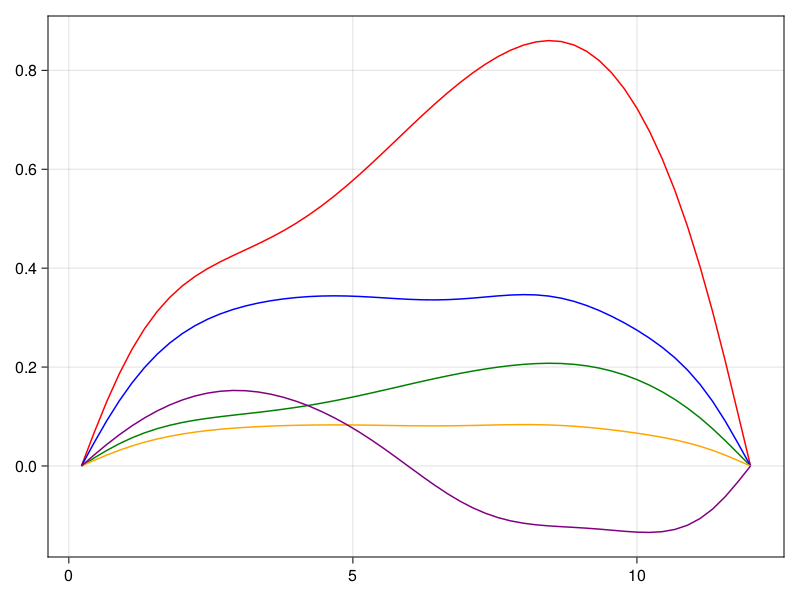

In [18]:
plot_control(accumulate(+, timesteps(prob.trajectory)), [3, 1, 5, 1, 1] .* prob.trajectory[:a])

In [ ]:
# function random_a_guess(traj::NamedTrajectory)
#     # Positive (symmetric) upper bounds
#     a_bounds = traj.bounds[:a][2]

#     a_dists = [Uniform(
#         -(a_bounds[i] == Inf ? 1.0 : a_bounds[i]),
#         (a_bounds[i] == Inf ? 1.0 : a_bounds[i])
#     ) for i = 1:traj.dims[:a]]

#     a = hcat([
#         zeros(traj.dims[:a]),
#         vcat([rand(a_dists[i], 1, T - 2) for i = 1:traj.dims[:a]]...),
#         zeros(traj.dims[:a])
#     ]...)
#     return a
# end

# Offset initial controls with amplitude contraint

Note: The option 1, where we don't stagger, led to pulses that were not good. The initialization via the stagger is important?

In [24]:
trajectory = copy(prob.trajectory)
# Need random initial conditions to avoid local minima

# Option 1:
# ----------------
# Don't stagger! Try to use the same order of magnitude as the initial gates.
# update!(trajectory, :a, [π/2/10 , π/2/10, π/4/10, π/4/10] .* random_a_guess(trajectory))
# update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)

# Option 2:
# ----------------
# Stagger as in the plot above?
update!(trajectory, :a, [3, 1, 5, 1, 1] .* prob.trajectory[:a])
update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)

parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += Objective(parameters[:objective_terms][1])
objective += QuadraticRegularizer(:dda, trajectory, 1e-3)
objective += QuadraticRegularizer(:a, trajectory, 1e-6)

update_bound!(trajectory, :a, 1.0)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-1

rob_prob_1 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9, 
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 63 * 0.003392208 = 0.21370910399999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(125844) MOI.VariableIndex(127907); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(125845) MOI.VariableIndex(127908); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(127905) MOI.VariableIndex(129968); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(127906) MOI.VariableIndex(129969)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2,

In [25]:
solve!(rob_prob_1; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_1))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_1))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  8687418
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:   127911
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      305
                     variables with only upper bounds:        0
Total number of equality constraints.................:   127596
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  8.9808645e+01 2.29e+00 1.13e-01   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  8.9900332e+01 2.27e+00 9.53e+01  -1.1 1.99e+00    -  1.00e+00 1.10e-02h  1


   2  7.3267807e+01 1.82e+00 1.62e+03   0.4 1.19e+01    -  4.02e-02 2.00e-01f  1


   3  7.1140112e+01 1.75e+00 3.16e+03   0.7 1.25e+01    -  3.69e-01 3.86e-02f  1


   4  5.3528215e+01 1.26e+00 8.87e+02   0.8 1.63e+01    -  1.95e-01 2.86e-01h  1


   5  4.7877574e+01 1.10e+00 3.77e+02  -0.0 2.21e+01    -  4.04e-01 1.26e-01h  1


... (66 outputs left out)

  72  5.7922613e-03 1.88e-03 1.57e+00  -4.0 7.32e-01    -  1.00e+00 8.26e-01h  1


  73  6.5000576e-03 1.13e-03 1.55e+00  -3.6 1.20e+00    -  5.00e-01 6.62e-01H  1


  74  5.7742130e-03 7.58e-04 1.56e+00  -4.0 5.02e-01    -  1.00e+00 1.00e+00h  1


  75  5.4223696e-03 2.51e-03 1.57e+00  -4.0 1.50e+00    -  1.00e+00 1.00e+00h  1

Number of Iterations....: 75

                                   (scaled)                 (unscaled)
Objective...............:   5.4223695552806997e-03    5.4223695552806997e-03
Dual infeasibility......:   1.5688576758849577e+00    1.5688576758849577e+00
Constraint violation....:   2.5056523103907935e-03    2.5056523103907935e-03
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.5491600896246372e-04    1.5491600896246372e-04
Overall NLP error.......:   1.5688576758849577e+00    1.5688576758849577e+00


Number of objective function evaluations             = 117
Number of objective gradient evaluations             = 76
Number of equality constraint evaluations            = 117
Number of inequality constraint evaluations          = 117
Number of equality constraint Jacobian evaluations   = 76
Number of inequality constraint Jacobian evaluations = 76
Nu

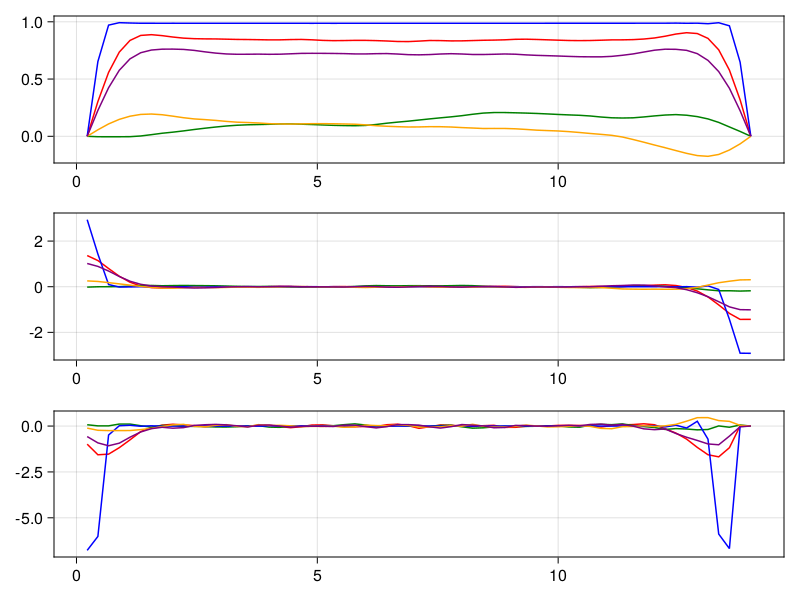

In [40]:
plot_control(rob_prob_1)

In [26]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-5)
objective += QuadraticRegularizer(:a, trajectory, 1e-5)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-1

rob_prob_2 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 63 * 0.003392208 = 0.21370910399999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(125844) MOI.VariableIndex(127907); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(125845) MOI.VariableIndex(127908); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(127905) MOI.VariableIndex(129968); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(127906) MOI.VariableIndex(129969)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2,

In [27]:
solve!(rob_prob_2; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_2))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_2))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  8687418
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:   127911
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:   127596
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  2.7719356e-04 2.51e-03 1.89e-03   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  2.7528486e-04 6.18e-03 1.09e+00  -4.0 2.71e-02    -  1.00e+00 3.65e-01h  1


   2  2.8180130e-04 2.49e-03 1.40e-02  -4.0 3.97e-01    -  1.00e+00 1.00e+00h  1


   3  2.7462072e-04 8.43e-04 9.12e-03  -4.0 1.24e-01    -  1.00e+00 1.00e+00h  1


   4  2.7300475e-04 3.10e-04 3.88e-03  -4.0 1.56e-01    -  1.00e+00 1.00e+00h  1


   5  2.7300210e-04 9.95e-05 1.15e-03  -4.0 9.69e-02    -  1.00e+00 1.00e+00h  1


... (67 outputs left out)

  73  8.9266265e-05 5.10e-05 4.08e-04  -3.9 3.19e-02    -  1.00e+00 1.00e+00h  1


  74  8.9519132e-05 1.67e-05 3.69e-04  -5.9 2.92e-02    -  1.00e+00 1.00e+00h  1


  75  8.8662259e-05 5.72e-05 8.93e-04  -4.0 3.55e-02    -  1.00e+00 1.00e+00h  1



Number of Iterations....: 75

                                   (scaled)                 (unscaled)
Objective...............:   8.8662258619640527e-05    8.8662258619640527e-05
Dual infeasibility......:   8.9256549639371140e-04    8.9256549639371140e-04
Constraint violation....:   5.7175695584943398e-05    5.7175695584943398e-05
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.4279686292988897e-04    1.4279686292988897e-04
Overall NLP error.......:   8.9256549639371140e-04    8.9256549639371140e-04


Number of objective function evaluations             = 142
Number of objective gradient evaluations             = 76
Number of equality constraint evaluations            = 146
Number of inequality constraint evaluations          = 146
Number of equality constraint Jacobian evaluations   = 76
Number of inequality constraint Jacobian evaluations = 76
Number of Lagrangian Hessian evaluations             = 0
Total seconds in IPOPT    

In [28]:
println("max(a): ", maximum(rob_prob_2.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_2.trajectory[:dda]))

max(a): 1.1828080086327704
max(dda): 0.786657773724313


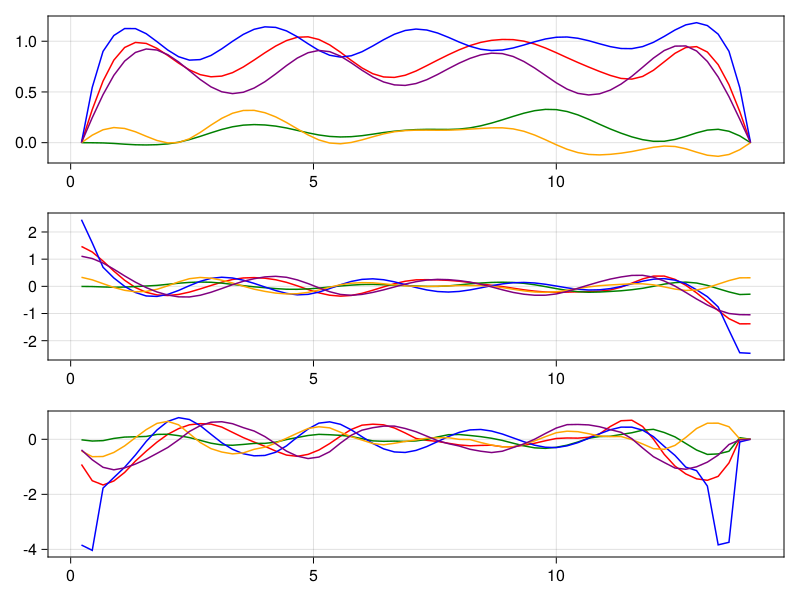

In [41]:
plot_control(rob_prob_2)

In [30]:
save("saved-pulses/single_qubit_gateset_R1e-5.jld2", rob_prob_2.trajectory)

In [31]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-5.csv", rob_prob_2.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, tighten R's

In [32]:
trajectory = copy(rob_prob_1.trajectory)
# Need random initial conditions to avoid local minima
# update!(trajectory, :a, random_a_guess(trajectory))
# update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-3)
objective += QuadraticRegularizer(:a, trajectory, 1e-3)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-1

rob_prob_3 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 63 * 0.003392208 = 0.21370910399999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(125844) MOI.VariableIndex(127907); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(125845) MOI.VariableIndex(127908); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(127905) MOI.VariableIndex(129968); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(127906) MOI.VariableIndex(129969)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2,

In [33]:
solve!(rob_prob_3; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_3))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_3))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  8687418
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:   127911
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:   127596
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  8.0738530e-03 2.51e-03 1.90e-03   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  8.0727631e-03 6.18e-03 1.09e+00  -4.0 2.71e-02    -  1.00e+00 3.65e-01h  1


   2  8.0911758e-03 2.24e-03 1.41e-02  -4.0 4.16e-01    -  1.00e+00 1.00e+00h  1


   3  7.9317870e-03 8.34e-04 8.63e-03  -4.0 1.42e-01    -  1.00e+00 1.00e+00h  1


   4  7.7952726e-03 2.94e-04 3.08e-03  -4.0 1.72e-01    -  1.00e+00 1.00e+00h  1


   5  7.5723892e-03 8.90e-05 6.79e-04  -4.0 2.24e-01    -  1.00e+00 1.00e+00h  1


... (66 outputs left out)

  72  3.9298892e-03 1.46e-04 2.97e-04  -4.8 7.34e-02    -  1.00e+00 1.00e+00h  1


  73  3.9269328e-03 3.83e-05 1.45e-02  -4.8 3.09e-02    -  1.00e+00 7.60e-01h  1


  74  3.9232832e-03 2.07e-05 1.29e-04  -4.8 4.01e-02    -  1.00e+00 1.00e+00h  1


  75  3.9202014e-03 9.19e-06 5.20e-05  -7.2 2.42e-02    -  1.00e+00 1.00e+00h  1

Number of Iterations....: 75

                                   (scaled)                 (unscaled)
Objective...............:   3.9202013848083344e-03    3.9202013848083344e-03
Dual infeasibility......:   5.2034732758774926e-05    5.2034732758774926e-05
Constraint violation....:   9.1861241867663423e-06    9.1861241867663423e-06
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   9.8328916374353414e-07    9.8328916374353414e-07
Overall NLP error.......:   9.9016710836256477e-05    9.9016710836256477e-05


Number of objective function evaluations             = 80
Number of objective gradient evaluations             = 76
Number of equality constraint evaluations            = 80
Number of inequality constraint evaluations          = 80
Number of equality constraint Jacobian evaluations   = 76
Number of inequality constraint Jacobian evaluations = 76
Numbe

In [34]:
println("max(a): ", maximum(rob_prob_3.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_3.trajectory[:dda]))

max(a): 1.2412423755552389
max(dda): 0.11622103694933059


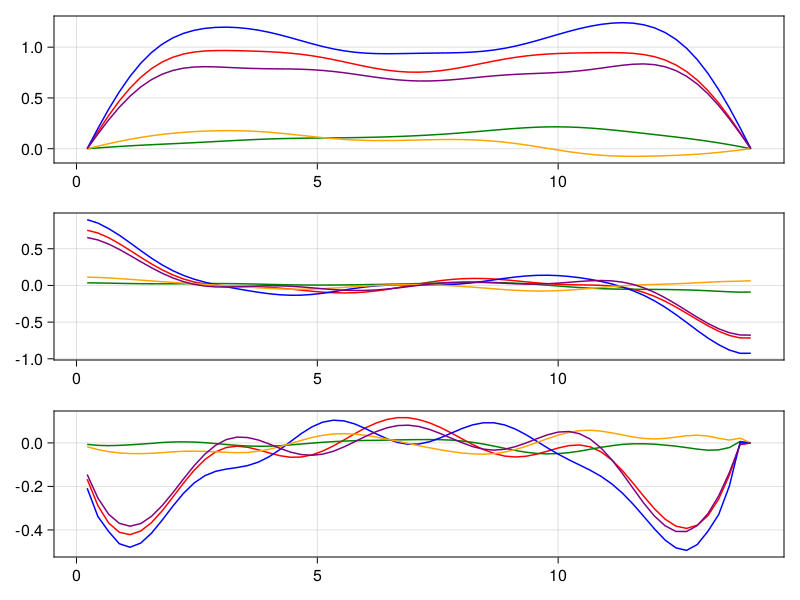

In [42]:
plot_control(rob_prob_3)

In [35]:
save("saved-pulses/single_qubit_gateset_R1e-3.jld2", rob_prob_3.trajectory)

In [36]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-3.csv", rob_prob_3.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, loosen R

In [ ]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-6)
objective += QuadraticRegularizer(:a, trajectory, 1e-6)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-1

rob_prob_4 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

In [ ]:
solve!(rob_prob_4; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_4))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_4))

In [ ]:
println("max(a): ", maximum(rob_prob_4.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_4.trajectory[:dda]))

In [43]:
plot_control(rob_prob_4)

UndefVarError: UndefVarError: `rob_prob_4` not defined

In [ ]:
save("saved-pulses/single_qubit_gateset_R1e-6.jld2", rob_prob_4.trajectory)

In [ ]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-6.csv", rob_prob_4.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, tightest constraint

In [ ]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-2)
objective += QuadraticRegularizer(:a, trajectory, 1e-2)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_5 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

In [ ]:
solve!(rob_prob_5; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_5))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_5))

In [ ]:
println("max(a): ", maximum(rob_prob_5.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_5.trajectory[:dda]))

In [ ]:
plot_control(rob_prob_5)

In [ ]:
save("saved-pulses/single_qubit_gateset_R1e-2.jld2", rob_prob_5.trajectory)

In [ ]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-2.csv", rob_prob_5.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, max regularization

In [ ]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-1)
objective += QuadraticRegularizer(:a, trajectory, 1e-1)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_6 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

In [ ]:
solve!(rob_prob_6; max_iter=50)

println("Fidelity: ", unitary_fidelity(rob_prob_6))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_6))

In [ ]:
println("max(a): ", maximum(rob_prob_6.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_6.trajectory[:dda]))

In [ ]:
plot_control(rob_prob_6)

In [ ]:
save("saved-pulses/single_qubit_gateset_R1e-1.jld2", rob_prob_6.trajectory)